# 01 · Portfolio monitoring with SQL

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/climate-tech-energy-finance/solar-loan-credit-risk/notebooks/01_portfolio_monitoring.ipynb)

A lender that finances solar panels, batteries and heat pumps through installer partners has to answer the same questions every month: how big is the book, how much of it is late, how are the older vintages ageing, and how much depends on a few installers.

This notebook answers them with the six queries in `sql/`, run against an in-memory SQLite copy of a synthetic loan book (10,000 loans, Germany and Austria, originated 2023 to 2025, observed on 31 Oct 2026).

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "climate-tech-energy-finance/solar-loan-credit-risk"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "solar_credit").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: solar-loan-credit-risk


## Load the loan book

The data is generated on first run if `data/` is empty. Borrowers and installers only appear as pseudonymous IDs.

In [2]:
from solar_credit.data_generator import load_loan_book
from solar_credit.monitoring import PortfolioDB, herfindahl_index, roll_rate_matrix
from solar_credit import reporting

book = load_loan_book()
print(f"{len(book.loans):,} loans, {len(book.performance):,} monthly performance rows, {len(book.installers)} installers")
book.loans.head(3)

10,000 loans, 231,537 monthly performance rows, 120 installers


,loan_id,installer_id,origination_date,country,region,region_unemployment_pct,product_type,loan_amount_eur,term_months,interest_rate,monthly_instalment_eur,system_kwp,expected_annual_savings_eur,savings_coverage_ratio,employment_type,net_monthly_income_eur,existing_debt_payments_eur,dti_ratio,bureau_score,installer_tenure_years,default_flag,default_mob,prepaid_flag,ead_at_default_eur,default_date,workout_closed_flag,recovery_eur
0,LN-000001,INST-0113,2024-11-02,DE,Baden-Wuerttemberg,4.3,HeatPump,21500.0,120,0.0580,236.54,0.0,510.0,0.180,Employee,3130.0,210.0,0.1427,684,8,0,NaN,0,NaN,NaT,0,NaN
1,LN-000002,INST-0016,2024-04-25,DE,Baden-Wuerttemberg,4.3,PV+Battery,17600.0,240,0.0477,113.93,7.7,1943.0,1.421,Employee,2530.0,350.0,0.1834,855,4,0,NaN,0,NaN,NaT,0,NaN
2,LN-000003,INST-0034,2025-12-20,DE,Nordrhein-Westfalen,7.5,PV,17700.0,180,0.0599,149.27,11.8,1862.0,1.040,Retired,4950.0,550.0,0.1413,718,24,0,NaN,0,NaN,NaT,0,NaN


In [3]:
db = PortfolioDB(book)
print(open("sql/01_portfolio_snapshot.sql").read())
db.run("01_portfolio_snapshot")

-- Live book at the observation date: open loans by status, with balance shares.
WITH latest AS (
    SELECT p.*
    FROM performance p
    WHERE p.as_of_date = (SELECT MAX(as_of_date) FROM performance)
      AND p.status IN ('Performing', 'Delinquent')
)
SELECT
    CASE
        WHEN days_past_due = 0  THEN '0 current'
        WHEN days_past_due = 30 THEN '1 DPD 30'
        WHEN days_past_due = 60 THEN '2 DPD 60'
        ELSE '3 DPD 90+'
    END                                                      AS dpd_bucket,
    COUNT(*)                                                 AS loans,
    ROUND(SUM(outstanding_balance_eur), 0)                   AS outstanding_eur,
    ROUND(SUM(outstanding_balance_eur) * 1.0
          / SUM(SUM(outstanding_balance_eur)) OVER (), 4)    AS share_of_balance
FROM latest
GROUP BY dpd_bucket
ORDER BY dpd_bucket;



,dpd_bucket,loans,outstanding_eur,share_of_balance
0,0 current,8468,154290830.0,0.9944
1,1 DPD 30,38,641316.0,0.0041
2,2 DPD 60,14,230977.0,0.0015


## Delinquency trend

Arrears are a small share of balance, which is what you'd expect from a book where most of the volume is less than two years old. The trend line matters more than the level: a rising 30+ share usually shows up three months before the defaults do.

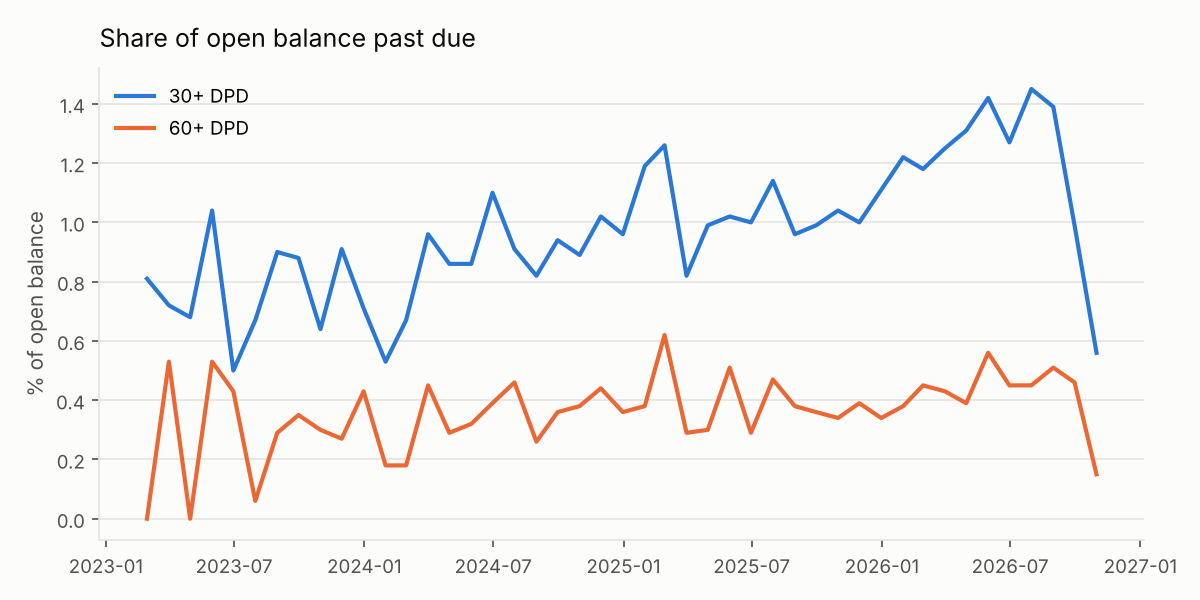

,as_of_date,open_loans,open_balance_eur,dpd30_plus_share,dpd60_plus_share,new_defaults,new_default_eur
40,2026-05-31,8797,165113966.0,0.0142,0.0056,23,416922.0
41,2026-06-30,8741,163089385.0,0.0127,0.0045,30,599922.0
42,2026-07-31,8683,161134967.0,0.0145,0.0045,22,416529.0
43,2026-08-31,8627,159134907.0,0.0139,0.0051,23,464624.0
44,2026-09-30,8574,157139731.0,0.0099,0.0046,28,562427.0
45,2026-10-31,8520,155163123.0,0.0056,0.0015,30,553240.0


In [4]:
trend = db.run("02_delinquency_trend")
display(Image(filename=str(reporting.plot_delinquency_trend(trend, Path("outputs/figures/delinquency_trend.png")))))
trend.tail(6)

## Vintage curves

Each line is a cohort of loans, tracked by months on book. The query cuts every vintage at the age its youngest open loan has reached, so a new vintage cannot look better just because it has had less time to go wrong.

The Q1 2023 cohort reached 4.0% cumulative defaults after 12 months, 9.4% after 24 and 12.5% after 36. Most defaults land in the first two years and the curve flattens in year three. The ECL model's lifetime PD assumes the same fading pattern. Later vintages are running below the 2023 ones at the same age.

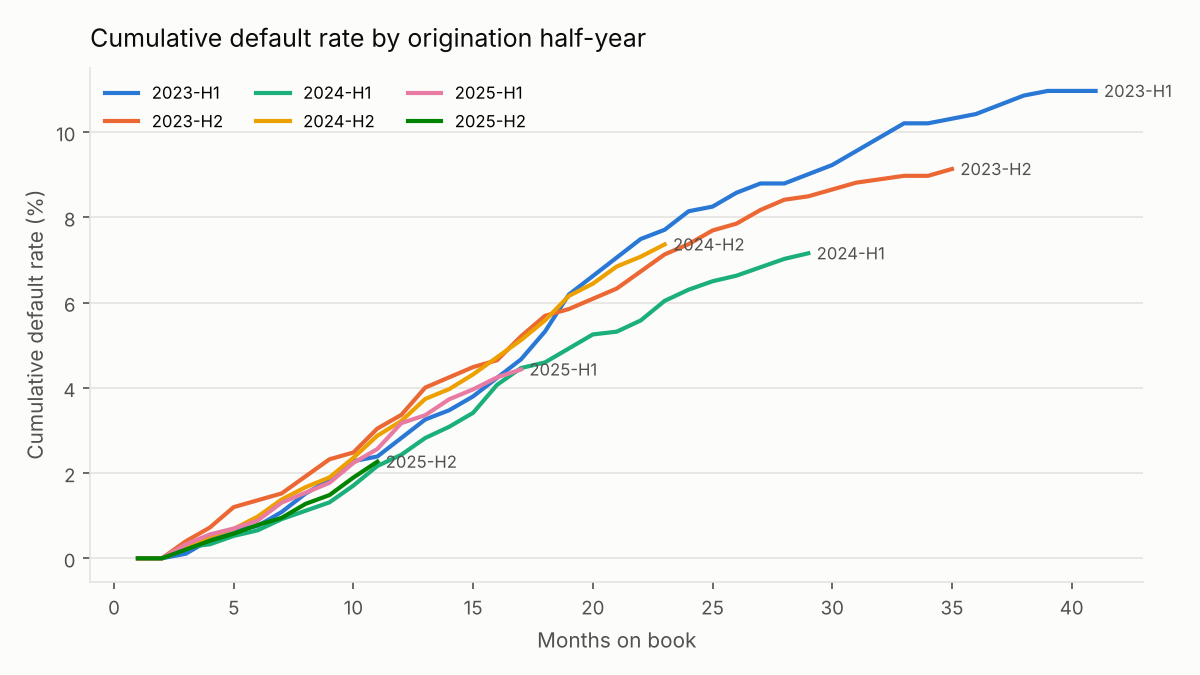

,cumulative_default_rate_to_date
vintage,
2023-Q1,0.1344
2023-Q2,0.0926
2023-Q3,0.0948
2023-Q4,0.0943
2024-Q1,0.0745
2024-Q2,0.0752
2024-Q3,0.0723
2024-Q4,0.0783
2025-Q1,0.0473


In [5]:
vintages = db.run("03_vintage_curves")
display(Image(filename=str(reporting.plot_vintage_curves(vintages, Path("outputs/figures/vintage_curves.png")))))
vintages.groupby("vintage")["cumulative_default_rate"].max().to_frame("cumulative_default_rate_to_date")

## Roll rates

A borrower who misses one payment cures about four times in ten. Once they reach 60 days past due, roughly three in four go on to default. That is why the ECL model moves every 30+ loan into stage 2 and uses observed roll-to-default rates for it, not the scorecard PD.

In [6]:
rolls = db.run("04_roll_rates")
roll_rate_matrix(rolls)

to_bucket,0 Current,1 DPD30,2 DPD60,4 Default,5 Prepaid
from_bucket,,,,,
0 Current,0.9896,0.007,0.0000,0.0000,0.0035
1 DPD30,0.4087,0.000,0.5873,0.0000,0.0040
2 DPD60,0.2338,0.000,0.0000,0.7662,0.0000


## Installer concentration

Installer partners are a credit risk of their own. If a large installer goes bust, customers lose their warranty and service contact, and recoveries on repossessed systems fall. The biggest partner here holds about 16% of open exposure, above a 10% single-name limit, even though the overall HHI looks unconcentrated. That gap is the point: HHI alone would not have raised the flag.

Installer HHI: 521.1


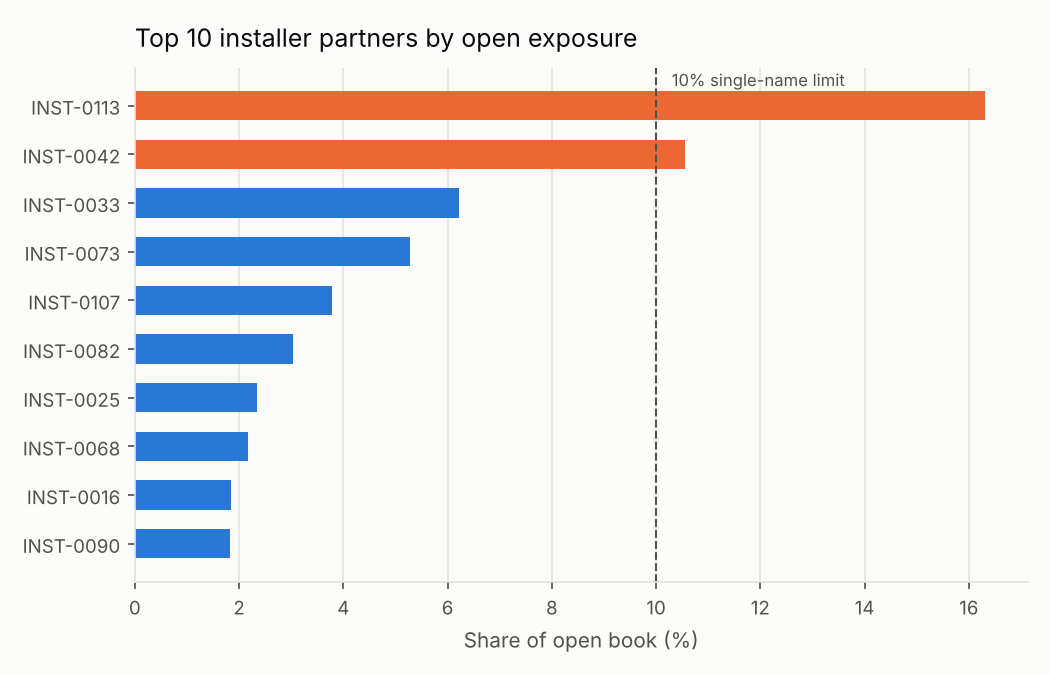

,installer_id,installer_region,installer_tenure_years,open_loans,exposure_eur,share_of_book,loans_written,lifetime_default_rate,exposure_rank
0,INST-0113,Baden-Wuerttemberg,8,1417,25309138.0,0.1631,1653,0.0617,1
1,INST-0042,Brandenburg,13,888,16374521.0,0.1055,1028,0.0642,2
2,INST-0033,Baden-Wuerttemberg,4,534,9637166.0,0.0621,621,0.0676,3
3,INST-0073,Schleswig-Holstein,3,446,8184336.0,0.0527,551,0.1034,4
4,INST-0107,Nordrhein-Westfalen,25,329,5873587.0,0.0379,382,0.0497,5
5,INST-0082,Nordrhein-Westfalen,3,261,4714640.0,0.0304,315,0.1079,6
6,INST-0025,Sachsen,25,192,3634591.0,0.0234,224,0.0357,7
7,INST-0068,Baden-Wuerttemberg,14,195,3387279.0,0.0218,213,0.0094,8
8,INST-0016,Baden-Wuerttemberg,4,165,2872388.0,0.0185,202,0.1040,9
9,INST-0090,Nordrhein-Westfalen,14,150,2833657.0,0.0183,174,0.0460,10


In [7]:
inst = db.run("05_installer_concentration")
print("Installer HHI:", herfindahl_index(inst["share_of_book"]))
display(Image(filename=str(reporting.plot_installer_concentration(inst, Path("outputs/figures/installer_concentration.png")))))
inst.head(10)

## Region and product mix

At book level, 1.3% of heat pump balance is 30+ days late, against 0.3% to 0.6% for the PV products. The median heat pump customer saves energy worth about 17% of the instalment; for PV with a battery it is above 100%.

In [8]:
seg = db.run("06_segment_mix")
seg["late_eur"] = seg["dpd30_plus_share"] * seg["exposure_eur"]
by_product = seg.groupby("product_type")[["exposure_eur", "late_eur"]].sum()
by_product["dpd30_plus_share"] = (by_product["late_eur"] / by_product["exposure_eur"]).round(4)
by_product.drop(columns="late_eur").sort_values("exposure_eur", ascending=False)

,exposure_eur,dpd30_plus_share
product_type,,
PV+Battery,68952338.0,0.0033
PV+Battery+Wallbox,29212526.0,0.0034
PV,28909689.0,0.0058
HeatPump,28088569.0,0.0134


In [9]:
db.close()